# Clustering Lanjutan pada Dataset Palmer Penguins

Notebook ini menerapkan empat algoritma clustering lanjutan, yaitu Agglomerative Clustering, DBSCAN, Gaussian Mixture Model (GMM), dan Spectral Clustering, pada data pengukuran fisik penguin. Empat kolom numerik dipakai sebagai fitur, sedangkan kolom `species` hanya dipakai sebagai label pembanding pada evaluasi eksternal.

Alur kerja mengikuti tugas Week 11: impor dataset, eksplorasi dan pembersihan, standardisasi, penerapan empat algoritma, evaluasi dengan Silhouette Score, Rand Index, dan NMI, serta uji kestabilan pada tiga sampel 90%.

> Notebook ini disusun oleh Benedictus Ryu Gunawan (5054251001) untuk Tugas Week 11 - Clustering Lanjutan.

# Import Library

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    rand_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# Konfigurasi

In [2]:
DATA_URL = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
FEATURES = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
SPECIES_COL = "species"
SEED = 42

ROOT_DIR = Path.cwd()
if not (ROOT_DIR / "output").exists() and (ROOT_DIR / "Week 11").exists():
    ROOT_DIR = ROOT_DIR / "Week 11"
OUTPUT_DIR = ROOT_DIR / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})

print(f"Root directory: {ROOT_DIR}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Seed: {SEED}")

Root directory: /home/ryz/data/collage/sem3/datmin/Repo/Week 11
Output directory: /home/ryz/data/collage/sem3/datmin/Repo/Week 11/output
Seed: 42


# Get Dataset

Dataset Palmer Penguins dibaca langsung dari URL resmi sehingga notebook tidak membutuhkan file data lokal. Dataset berisi 344 baris pengukuran penguin dari Kepulauan Palmer, Antartika.

In [3]:
t0 = time.time()
df_raw = pd.read_csv(DATA_URL)
print(f"Waktu baca data: {time.time() - t0:.2f} detik")
print(f"Shape dataset: {df_raw.shape}")
display(df_raw.head())

Waktu baca data: 0.51 detik
Shape dataset: (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [4]:
print("=== df_raw.info() ===")
df_raw.info()
print("\n=== Kolom ===")
print(df_raw.columns.tolist())
print("\n=== Tipe data ===")
display(df_raw.dtypes.to_frame("tipe"))

=== df_raw.info() ===
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 27.6 KB

=== Kolom ===
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']

=== Tipe data ===


,tipe
species,str
island,str
bill_length_mm,float64
bill_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,str
year,int64


# Eksplorasi dan Pembersihan Data

,n_missing,persen (%)
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20
year,0,0.00


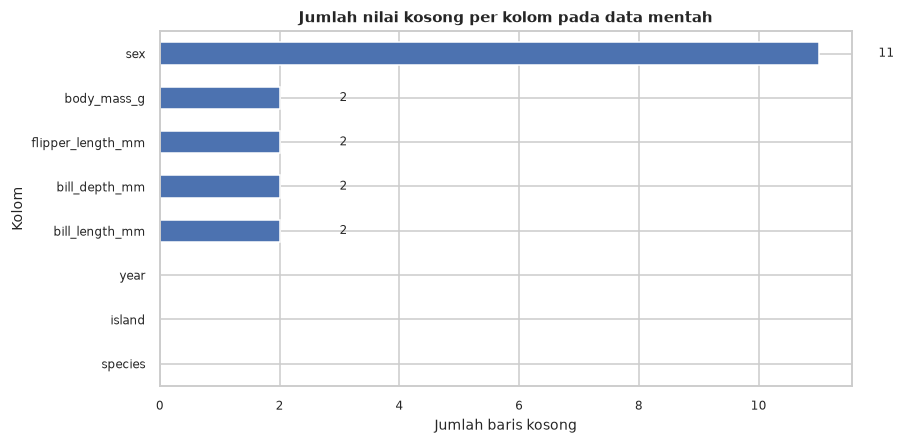

In [5]:
missing = df_raw.isna().sum().to_frame("n_missing")
missing["persen (%)"] = (missing["n_missing"] / len(df_raw) * 100).round(2)
display(missing)

fig, ax = plt.subplots(figsize=(8.4, 4.2))
missing["n_missing"].sort_values().plot(kind="barh", color="#4c72b0", ax=ax)
ax.set_title("Jumlah nilai kosong per kolom pada data mentah", fontsize=10, fontweight="bold")
ax.set_xlabel("Jumlah baris kosong", fontsize=9)
ax.set_ylabel("Kolom", fontsize=9)
ax.tick_params(labelsize=8)
for i, value in enumerate(missing["n_missing"].sort_values()):
    if value > 0:
        ax.text(value + 1, i, str(value), va="center", fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "missing_values.png", bbox_inches="tight")
plt.show()


Baris yang kosong pada salah satu dari empat fitur numerik atau pada kolom `species` dihapus. Kolom `sex` juga memiliki nilai kosong, tetapi kolom tersebut tidak dipakai dalam clustering sehingga tidak menjadi dasar penghapusan.

In [6]:
before = len(df_raw)
df = df_raw.dropna(subset=FEATURES + [SPECIES_COL]).reset_index(drop=True)
after = len(df)
removed = before - after

cleaning_summary = pd.DataFrame({
    "tahap": ["Data mentah", "Hapus missing fitur atau species"],
    "baris": [before, after],
    "baris_dihapus": [0, removed],
})
display(cleaning_summary)
print(f"Baris sebelum: {before:,}")
print(f"Baris sesudah: {after:,}")
print(f"Baris dihapus: {removed:,} ({removed / before * 100:.2f}%)")
print("\nMissing values setelah pembersihan:")
display(df.isna().sum().to_frame("n_missing"))

species_counts = (
    df[SPECIES_COL]
    .value_counts()
    .rename_axis("species")
    .reset_index(name="n")
)
species_counts["persen (%)"] = (species_counts["n"] / len(df) * 100).round(2)
display(species_counts)

cleaning_summary.to_csv(OUTPUT_DIR / "cleaning_summary.csv", index=False)
species_counts.to_csv(OUTPUT_DIR / "species_counts.csv", index=False)

,tahap,baris,baris_dihapus
0,Data mentah,344,0
1,Hapus missing fitur atau species,342,2


Baris sebelum: 344
Baris sesudah: 342
Baris dihapus: 2 (0.58%)

Missing values setelah pembersihan:


,n_missing
species,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,9
year,0


,species,n,persen (%)
0,Adelie,151,44.15
1,Gentoo,123,35.96
2,Chinstrap,68,19.88


Statistik deskriptif berikut menunjukkan perbedaan skala yang besar. `body_mass_g` memiliki simpangan baku sekitar 802 gram, sedangkan `bill_depth_mm` hanya sekitar 1,97 milimeter. Karena itu standardisasi wajib dilakukan sebelum clustering.

In [7]:
feature_stats = df[FEATURES].describe().T
feature_stats["range"] = feature_stats["max"] - feature_stats["min"]
display(feature_stats.round(2))
print(f"Rasio simpangan baku terbesar terhadap terkecil: {feature_stats['std'].max() / feature_stats['std'].min():.1f}x")
feature_stats.to_csv(OUTPUT_DIR / "feature_stats.csv")

,count,mean,std,min,25%,50%,75%,max,range
bill_length_mm,342.0,43.92,5.46,32.1,39.22,44.45,48.5,59.6,27.5
bill_depth_mm,342.0,17.15,1.97,13.1,15.60,17.30,18.7,21.5,8.4
flipper_length_mm,342.0,200.92,14.06,172.0,190.00,197.00,213.0,231.0,59.0
body_mass_g,342.0,4201.75,801.95,2700.0,3550.00,4050.00,4750.0,6300.0,3600.0


Rasio simpangan baku terbesar terhadap terkecil: 406.1x


Scatter plot awal memakai `bill_length_mm` pada sumbu x dan `flipper_length_mm` pada sumbu y. Panel kiri menampilkan sebaran tanpa label, sedangkan panel kanan memberi warna berdasarkan spesies hanya sebagai referensi visual. Kolom `species` tidak dipakai oleh algoritma clustering.

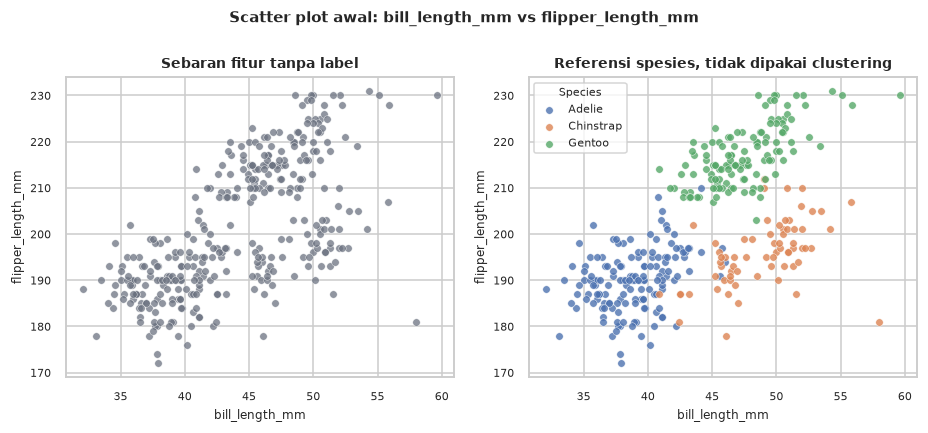

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(8.6, 4.0))

axes[0].scatter(
    df["bill_length_mm"], df["flipper_length_mm"],
    s=24, color="#6b7280", alpha=0.75, edgecolor="white", linewidth=0.35,
)
axes[0].set_title("Sebaran fitur tanpa label", fontsize=9, fontweight="bold")
axes[0].set_xlabel("bill_length_mm", fontsize=8)
axes[0].set_ylabel("flipper_length_mm", fontsize=8)
axes[0].tick_params(labelsize=7.5)

palette = {"Adelie": "#4c72b0", "Chinstrap": "#dd8452", "Gentoo": "#55a868"}
for species, group in df.groupby(SPECIES_COL):
    axes[1].scatter(
        group["bill_length_mm"], group["flipper_length_mm"],
        s=24, alpha=0.8, color=palette[species], label=species,
        edgecolor="white", linewidth=0.35,
    )
axes[1].set_title("Referensi spesies, tidak dipakai clustering", fontsize=9, fontweight="bold")
axes[1].set_xlabel("bill_length_mm", fontsize=8)
axes[1].set_ylabel("flipper_length_mm", fontsize=8)
axes[1].tick_params(labelsize=7.5)
axes[1].legend(title="Species", fontsize=7, title_fontsize=7)

fig.suptitle("Scatter plot awal: bill_length_mm vs flipper_length_mm", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "initial_scatter.png", bbox_inches="tight")
plt.show()


# Standardisasi Data

Matriks fitur `X` berisi empat kolom numerik, sedangkan `y` berisi label spesies untuk evaluasi. StandardScaler mengubah setiap fitur menjadi z-score dengan rata-rata 0 dan simpangan baku 1.

,count,mean,std,min,25%,50%,75%,max
bill_length_mm,342.0,0.0,1.001,-2.169,-0.862,0.097,0.840,2.876
bill_depth_mm,342.0,0.0,1.001,-2.054,-0.787,0.075,0.785,2.205
flipper_length_mm,342.0,-0.0,1.001,-2.059,-0.777,-0.279,0.861,2.143
body_mass_g,342.0,0.0,1.001,-1.875,-0.814,-0.190,0.685,2.620


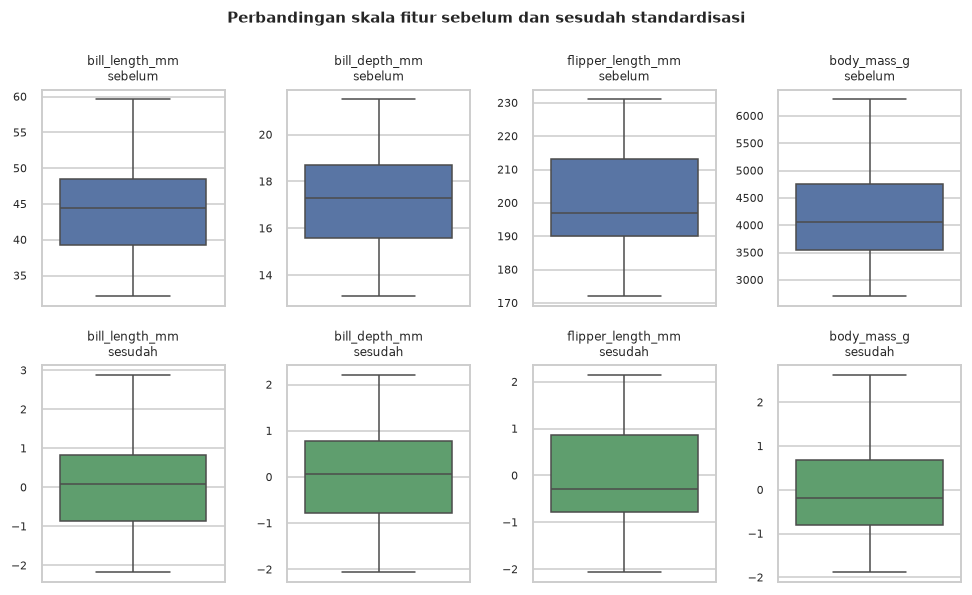

In [9]:
X = df[FEATURES].to_numpy()
y = df[SPECIES_COL].to_numpy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scaled_stats = pd.DataFrame(X_scaled, columns=FEATURES).describe().T
display(scaled_stats.round(3))
scaled_stats.to_csv(OUTPUT_DIR / "scaled_feature_stats.csv")

fig, axes = plt.subplots(2, 4, figsize=(9, 5.5))
for j, col in enumerate(FEATURES):
    sns.boxplot(y=df[col], ax=axes[0, j], color="#4c72b0")
    axes[0, j].set_title(f"{col}\nsebelum", fontsize=8)
    axes[0, j].set_ylabel("")
    axes[0, j].tick_params(labelsize=7)
    sns.boxplot(y=X_scaled[:, j], ax=axes[1, j], color="#55a868")
    axes[1, j].set_title(f"{col}\nsesudah", fontsize=8)
    axes[1, j].set_ylabel("")
    axes[1, j].tick_params(labelsize=7)
fig.suptitle("Perbandingan skala fitur sebelum dan sesudah standardisasi", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "scaling_comparison.png", bbox_inches="tight")
plt.show()


# Penerapan Algoritma

Fungsi evaluasi berikut menghitung jumlah kluster, jumlah noise, Silhouette Score, Rand Index, NMI, dan Adjusted Rand Index (ARI). Silhouette dihitung pada titik non-noise. Rand Index dan NMI utama dihitung pada seluruh titik dengan noise DBSCAN sebagai label -1. Untuk DBSCAN juga disimpan nilai Rand Index dan NMI pada titik non-noise sebagai pembanding.

In [10]:
def evaluate_clustering(name, labels):
    labels = np.asarray(labels)
    mask = labels != -1
    n_clusters = len(np.unique(labels[mask]))
    n_noise = int((labels == -1).sum())
    sil = (
        silhouette_score(X_scaled[mask], labels[mask])
        if n_clusters > 1
        else np.nan
    )
    row = {
        "algoritma": name,
        "n_clusters": n_clusters,
        "n_noise": n_noise,
        "n_eval_silhouette": int(mask.sum()),
        "silhouette": sil,
        "rand_index": rand_score(y, labels),
        "nmi": normalized_mutual_info_score(y, labels),
        "ari": adjusted_rand_score(y, labels),
        "rand_index_nonnoise": np.nan,
        "nmi_nonnoise": np.nan,
    }
    if n_noise:
        row["rand_index_nonnoise"] = rand_score(y[mask], labels[mask])
        row["nmi_nonnoise"] = normalized_mutual_info_score(y[mask], labels[mask])
    return row


def cluster_counts(labels):
    return pd.Series(labels).value_counts().sort_index().to_frame("jumlah")

## Agglomerative Clustering

Agglomerative Clustering dijalankan dengan tiga kluster dan Ward linkage. Ward linkage memilih penggabungan yang meminimalkan kenaikan total variansi dalam kluster, sehingga cocok untuk fitur numerik yang sudah distandardisasi.

In [11]:
agg = AgglomerativeClustering(n_clusters=3, linkage="ward")
agg_labels = agg.fit_predict(X_scaled)
agg_metrics = evaluate_clustering("Agglomerative (Ward)", agg_labels)
display(pd.DataFrame([agg_metrics]).round(4))
display(cluster_counts(agg_labels))

,algoritma,n_clusters,n_noise,n_eval_silhouette,silhouette,rand_index,nmi,ari,rand_index_nonnoise,nmi_nonnoise
0,Agglomerative (Ward),3,0,342,0.4541,0.9608,0.9007,0.9159,NaN,NaN


,jumlah
0,162
1,123
2,57


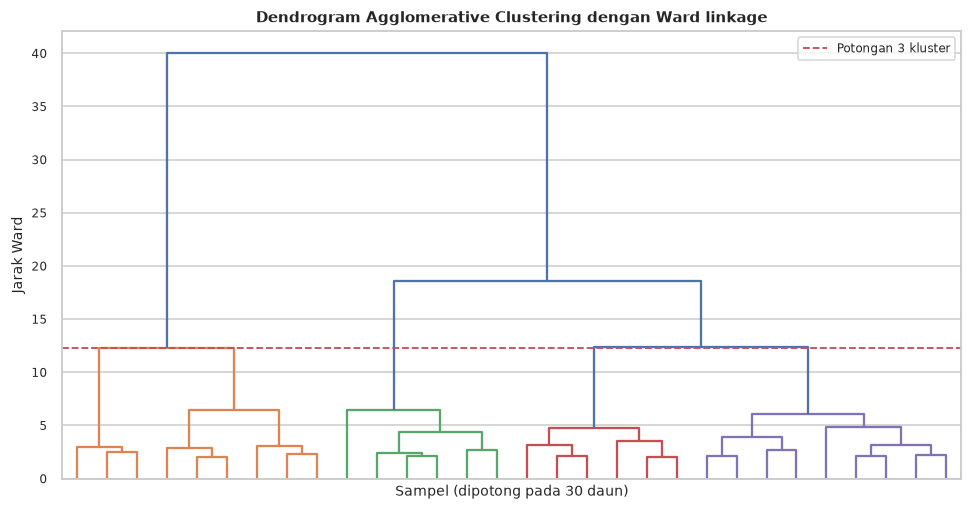

In [12]:
Z = linkage(X_scaled, method="ward")
cut_height = (Z[-4, 2] + Z[-3, 2]) / 2

fig, ax = plt.subplots(figsize=(9, 4.8))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    no_labels=True,
    color_threshold=cut_height,
    ax=ax,
)
ax.axhline(cut_height, color="#c44e52", linestyle="--", linewidth=1.2, label="Potongan 3 kluster")
ax.set_title("Dendrogram Agglomerative Clustering dengan Ward linkage", fontsize=10, fontweight="bold")
ax.set_xlabel("Sampel (dipotong pada 30 daun)", fontsize=9)
ax.set_ylabel("Jarak Ward", fontsize=9)
ax.tick_params(labelsize=8)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "dendrogram.png", bbox_inches="tight")
plt.show()


## DBSCAN

DBSCAN dimulai dari `eps=0.5` dan `min_samples=5`. Nilai eps kemudian diuji pada beberapa nilai lain untuk melihat trade-off antara jumlah kluster, jumlah noise, dan kualitas pemisahan. Nilai `eps=0.55` dipilih untuk perbandingan utama karena menghasilkan tiga kluster dengan noise yang masih terkendali dan metrik eksternal yang baik.

In [13]:
db_base_labels = DBSCAN(eps=0.5, min_samples=5).fit_predict(X_scaled)
db_base_metrics = evaluate_clustering("DBSCAN (eps=0.50)", db_base_labels)
display(pd.DataFrame([db_base_metrics]).round(4))
display(cluster_counts(db_base_labels))

,algoritma,n_clusters,n_noise,n_eval_silhouette,silhouette,rand_index,nmi,ari,rand_index_nonnoise,nmi_nonnoise
0,DBSCAN (eps=0.50),4,69,273,0.4235,0.8525,0.6631,0.6632,0.9764,0.9105


,jumlah
-1,69
0,118
1,113
2,15
3,27


,eps,n_clusters,n_noise,silhouette,rand_index,nmi,ari
0,0.40,10,171,0.3822,0.6222,0.3840,0.1503
1,0.45,5,108,0.2336,0.7701,0.5590,0.4718
2,0.50,4,69,0.4235,0.8525,0.6631,0.6632
3,0.52,3,60,0.5095,0.8771,0.7084,0.7218
4,0.54,3,48,0.5006,0.8936,0.7328,0.7604
5,0.55,3,46,0.4998,0.8959,0.7386,0.7655
6,0.56,3,44,0.4976,0.9001,0.7439,0.7754
7,0.58,3,39,0.4931,0.9018,0.7441,0.7801
8,0.60,2,33,0.5572,0.7989,0.6151,0.5844
9,0.70,2,16,0.5509,0.8209,0.6832,0.6394


,algoritma,n_clusters,n_noise,n_eval_silhouette,silhouette,rand_index,nmi,ari,rand_index_nonnoise,nmi_nonnoise
0,DBSCAN (eps=0.55),3,46,296,0.4998,0.8959,0.7386,0.7655,0.9838,0.9475


,jumlah
-1,46
0,131
1,115
2,50


Titik noise: 46 dari 342 (13.45%)
Metrik non-noise: RI 0.9838, NMI 0.9475


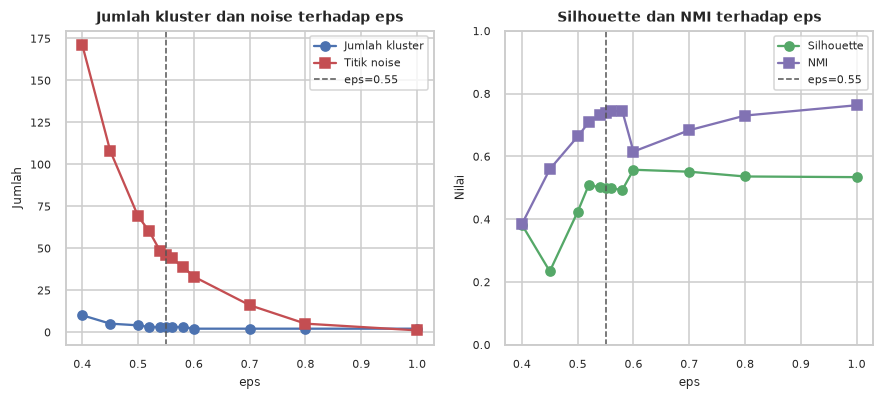

In [14]:
eps_values = [0.40, 0.45, 0.50, 0.52, 0.54, 0.55, 0.56, 0.58, 0.60, 0.70, 0.80, 1.00]
sweep_rows = []
for eps in eps_values:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
    row = evaluate_clustering(f"DBSCAN (eps={eps:.2f})", labels)
    row["eps"] = eps
    sweep_rows.append(row)

db_sweep = pd.DataFrame(sweep_rows)
display(db_sweep[["eps", "n_clusters", "n_noise", "silhouette", "rand_index", "nmi", "ari"]].round(4))
db_sweep.to_csv(OUTPUT_DIR / "dbscan_eps_sweep.csv", index=False)

DBSCAN_EPS = 0.55
DBSCAN_MIN_SAMPLES = 5
db_labels = DBSCAN(eps=DBSCAN_EPS, min_samples=DBSCAN_MIN_SAMPLES).fit_predict(X_scaled)
db_metrics = evaluate_clustering(f"DBSCAN (eps={DBSCAN_EPS:.2f})", db_labels)
display(pd.DataFrame([db_metrics]).round(4))
display(cluster_counts(db_labels))
print(f"Titik noise: {db_metrics['n_noise']} dari {len(df)} ({db_metrics['n_noise'] / len(df) * 100:.2f}%)")
print(f"Metrik non-noise: RI {db_metrics['rand_index_nonnoise']:.4f}, NMI {db_metrics['nmi_nonnoise']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.8))
axes[0].plot(db_sweep["eps"], db_sweep["n_clusters"], marker="o", color="#4c72b0", label="Jumlah kluster")
axes[0].plot(db_sweep["eps"], db_sweep["n_noise"], marker="s", color="#c44e52", label="Titik noise")
axes[0].axvline(DBSCAN_EPS, color="#555555", linestyle="--", linewidth=1, label=f"eps={DBSCAN_EPS:.2f}")
axes[0].set_title("Jumlah kluster dan noise terhadap eps", fontsize=9, fontweight="bold")
axes[0].set_xlabel("eps", fontsize=8)
axes[0].set_ylabel("Jumlah", fontsize=8)
axes[0].tick_params(labelsize=7.5)
axes[0].legend(fontsize=7)

axes[1].plot(db_sweep["eps"], db_sweep["silhouette"], marker="o", color="#55a868", label="Silhouette")
axes[1].plot(db_sweep["eps"], db_sweep["nmi"], marker="s", color="#8172b3", label="NMI")
axes[1].axvline(DBSCAN_EPS, color="#555555", linestyle="--", linewidth=1, label=f"eps={DBSCAN_EPS:.2f}")
axes[1].set_title("Silhouette dan NMI terhadap eps", fontsize=9, fontweight="bold")
axes[1].set_xlabel("eps", fontsize=8)
axes[1].set_ylabel("Nilai", fontsize=8)
axes[1].set_ylim(0, 1)
axes[1].tick_params(labelsize=7.5)
axes[1].legend(fontsize=7)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "dbscan_eps_sweep.png", bbox_inches="tight")
plt.show()


## Gaussian Mixture Model

GMM memodelkan data sebagai campuran tiga distribusi Gaussian dengan full covariance. Setiap titik memiliki probabilitas keanggotaan pada setiap komponen, lalu label akhir diambil dari komponen dengan probabilitas tertinggi.

,algoritma,n_clusters,n_noise,n_eval_silhouette,silhouette,rand_index,nmi,ari,rand_index_nonnoise,nmi_nonnoise
0,GMM (3 komponen),3,0,342,0.4545,0.9817,0.9349,0.9603,NaN,NaN


,jumlah
0,123
1,152
2,67


species,Adelie,Chinstrap,Gentoo
cluster,,,
0,0,0,123
1,149,3,0
2,2,65,0


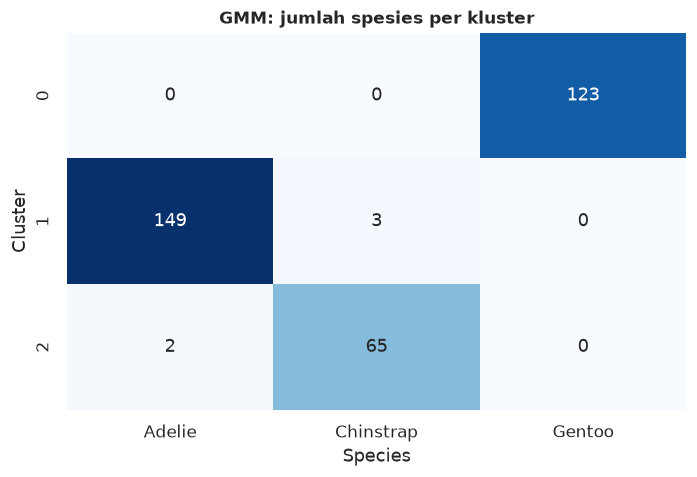

In [15]:
gmm = GaussianMixture(
    n_components=3,
    covariance_type="full",
    random_state=SEED,
    n_init=10,
)
gmm_labels = gmm.fit_predict(X_scaled)
gmm_metrics = evaluate_clustering("GMM (3 komponen)", gmm_labels)
display(pd.DataFrame([gmm_metrics]).round(4))
display(cluster_counts(gmm_labels))

gmm_crosstab = pd.crosstab(
    pd.Series(gmm_labels, name="cluster"),
    pd.Series(y, name="species"),
)
display(gmm_crosstab)
gmm_crosstab.to_csv(OUTPUT_DIR / "gmm_species_crosstab.csv")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.heatmap(gmm_crosstab, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("GMM: jumlah spesies per kluster", fontsize=11, fontweight="bold")
ax.set_xlabel("Species")
ax.set_ylabel("Cluster")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "gmm_species_heatmap.png", bbox_inches="tight")
plt.show()

## Spectral Clustering

Spectral Clustering dijalankan dengan tiga kluster, `n_neighbors=10`, dan `assign_labels="kmeans"`. Algoritma ini membangun graf kemiripan antar titik, lalu mempartisi graf tersebut menggunakan vektor eigen dari matriks Laplacian.

In [16]:
spectral = SpectralClustering(
    n_clusters=3,
    n_neighbors=10,
    assign_labels="kmeans",
    random_state=SEED,
)
spec_labels = spectral.fit_predict(X_scaled)
spec_metrics = evaluate_clustering("Spectral (3 kluster)", spec_labels)
display(pd.DataFrame([spec_metrics]).round(4))
display(cluster_counts(spec_labels))

,algoritma,n_clusters,n_noise,n_eval_silhouette,silhouette,rand_index,nmi,ari,rand_index_nonnoise,nmi_nonnoise
0,Spectral (3 kluster),3,0,342,0.4624,0.9168,0.8312,0.8248,NaN,NaN


,jumlah
0,176
1,123
2,43


# Visualisasi Hasil Clustering

Scatter plot berikut memakai dua fitur asli, yaitu `bill_length_mm` dan `flipper_length_mm`, agar hasil mudah dibandingkan dengan scatter plot awal. Clustering tetap dijalankan pada empat fitur yang sudah distandardisasi, sehingga gambar ini adalah proyeksi dua dimensi dari ruang empat dimensi. Label kluster bersifat arbitrer dan warna antar algoritma tidak saling berkorespondensi.

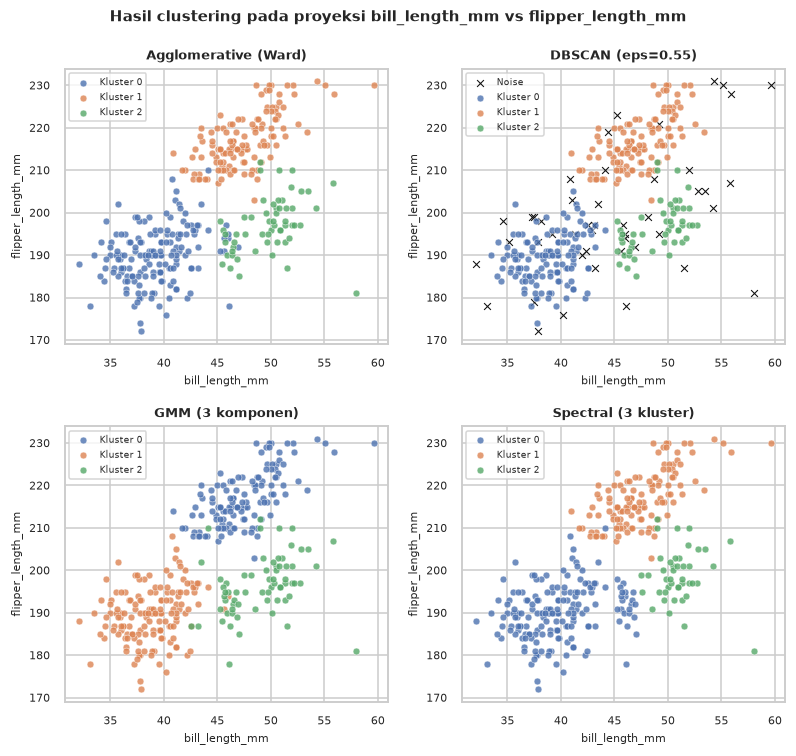

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(7.4, 7.0))
algorithm_labels = [
    ("Agglomerative (Ward)", agg_labels),
    (f"DBSCAN (eps={DBSCAN_EPS:.2f})", db_labels),
    ("GMM (3 komponen)", gmm_labels),
    ("Spectral (3 kluster)", spec_labels),
]
cluster_palette = ["#4c72b0", "#dd8452", "#55a868", "#8172b3", "#937860"]

for ax, (name, labels) in zip(axes.ravel(), algorithm_labels):
    if name.startswith("DBSCAN"):
        noise = labels == -1
        ax.scatter(
            df.loc[noise, "bill_length_mm"], df.loc[noise, "flipper_length_mm"],
            s=20, color="#111111", marker="x", linewidths=0.7, label="Noise",
        )
        for k in sorted(set(labels) - {-1}):
            mask = labels == k
            ax.scatter(
                df.loc[mask, "bill_length_mm"], df.loc[mask, "flipper_length_mm"],
                s=20, alpha=0.8, color=cluster_palette[k % len(cluster_palette)],
                edgecolor="white", linewidth=0.35, label=f"Kluster {k}",
            )
    else:
        for k in sorted(set(labels)):
            mask = labels == k
            ax.scatter(
                df.loc[mask, "bill_length_mm"], df.loc[mask, "flipper_length_mm"],
                s=20, alpha=0.8, color=cluster_palette[k % len(cluster_palette)],
                edgecolor="white", linewidth=0.35, label=f"Kluster {k}",
            )
    ax.set_title(name, fontsize=8.5, fontweight="bold")
    ax.set_xlabel("bill_length_mm", fontsize=7.5)
    ax.set_ylabel("flipper_length_mm", fontsize=7.5)
    ax.tick_params(labelsize=7)
    ax.legend(fontsize=6.2, loc="best")

fig.suptitle("Hasil clustering pada proyeksi bill_length_mm vs flipper_length_mm", fontsize=9.5, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cluster_comparison.png", bbox_inches="tight")
plt.show()

assignments = df.copy()
assignments["agglomerative_ward"] = agg_labels
assignments["dbscan"] = db_labels
assignments["gmm"] = gmm_labels
assignments["spectral"] = spec_labels
assignments.to_csv(OUTPUT_DIR / "cluster_assignments.csv", index=False)


# Evaluasi Hasil Clustering

Silhouette Score mengukur kohesi dan pemisahan kluster tanpa memakai label spesies. Rand Index dan NMI mengukur kesesuaian kluster dengan spesies. Untuk DBSCAN, Silhouette dihitung pada titik non-noise, sedangkan Rand Index dan NMI utama dihitung pada seluruh titik dengan noise sebagai label -1.

,algoritma,n_clusters,n_noise,n_eval_silhouette,silhouette,rand_index,nmi,ari
0,Agglomerative (Ward),3,0,342,0.4541,0.9608,0.9007,0.9159
1,DBSCAN (eps=0.55),3,46,296,0.4998,0.8959,0.7386,0.7655
2,GMM (3 komponen),3,0,342,0.4545,0.9817,0.9349,0.9603
3,Spectral (3 kluster),3,0,342,0.4624,0.9168,0.8312,0.8248


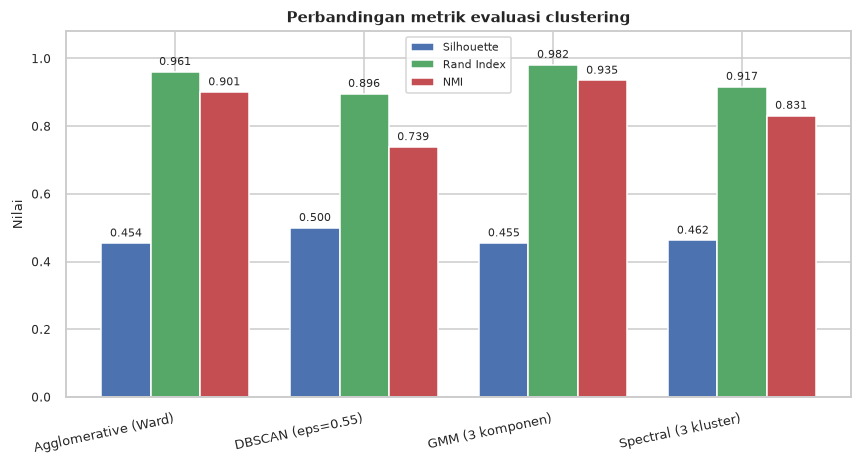

In [18]:
metrics_df = pd.DataFrame([agg_metrics, db_metrics, gmm_metrics, spec_metrics])
metrics_df = metrics_df[
    ["algoritma", "n_clusters", "n_noise", "n_eval_silhouette",
     "silhouette", "rand_index", "nmi", "ari"]
]
display(metrics_df.round(4))
metrics_df.to_csv(OUTPUT_DIR / "clustering_metrics.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.4))
x = np.arange(len(metrics_df))
width = 0.26
ax.bar(x - width, metrics_df["silhouette"], width, label="Silhouette", color="#4c72b0")
ax.bar(x, metrics_df["rand_index"], width, label="Rand Index", color="#55a868")
ax.bar(x + width, metrics_df["nmi"], width, label="NMI", color="#c44e52")
ax.set_xticks(x)
ax.set_xticklabels(metrics_df["algoritma"], rotation=12, ha="right", fontsize=8.5)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Nilai", fontsize=8.5)
ax.set_title("Perbandingan metrik evaluasi clustering", fontsize=10, fontweight="bold")
ax.tick_params(axis="y", labelsize=8)
ax.legend(fontsize=7.5)
for i, row in metrics_df.iterrows():
    ax.text(i - width, row["silhouette"] + 0.02, f"{row['silhouette']:.3f}", ha="center", fontsize=7.5)
    ax.text(i, row["rand_index"] + 0.02, f"{row['rand_index']:.3f}", ha="center", fontsize=7.5)
    ax.text(i + width, row["nmi"] + 0.02, f"{row['nmi']:.3f}", ha="center", fontsize=7.5)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "metrics_comparison.png", bbox_inches="tight")
plt.show()


# Uji Kestabilan

Uji kestabilan menjalankan ulang setiap algoritma pada 90% data yang diambil acak tanpa pengembalian, sebanyak tiga kali dengan seed 42, 43, dan 44. Hasil setiap sampel dibandingkan dengan hasil data penuh pada titik yang sama menggunakan ARI dan NMI. Nilai yang tinggi menunjukkan partisi yang konsisten terhadap perubahan kecil pada dataset.

,algoritma,stability_ari_mean,stability_ari_std,stability_nmi_mean,stability_nmi_std,subsample_silhouette_mean,subsample_silhouette_std,subsample_clusters_mean,subsample_noise_mean
0,Agglomerative (Ward),0.7406,0.1351,0.7983,0.0819,0.4356,0.0131,3.0000,0.0
1,DBSCAN (eps=0.55),0.9491,0.0393,0.9260,0.0413,0.4576,0.0617,3.6667,44.0
2,GMM (3 komponen),0.9883,0.0109,0.9805,0.0170,0.4544,0.0018,3.0000,0.0
3,Spectral (3 kluster),1.0000,0.0000,1.0000,0.0000,0.4593,0.0014,3.0000,0.0


,algoritma,seed,ari_vs_full,nmi_vs_full,silhouette_subsample,n_clusters,n_noise
0,Agglomerative (Ward),42,0.6444,0.7410,0.4252,3,0
1,Agglomerative (Ward),43,0.6459,0.7397,0.4274,3,0
2,Agglomerative (Ward),44,0.9316,0.9141,0.4541,3,0
3,DBSCAN (eps=0.55),42,0.8941,0.8691,0.3705,5,45
4,DBSCAN (eps=0.55),43,0.9695,0.9429,0.5057,3,45
5,DBSCAN (eps=0.55),44,0.9836,0.9660,0.4966,3,42
6,GMM (3 komponen),42,1.0000,1.0000,0.4518,3,0
7,GMM (3 komponen),43,0.9738,0.9586,0.4554,3,0
8,GMM (3 komponen),44,0.9911,0.9828,0.4560,3,0
9,Spectral (3 kluster),42,1.0000,1.0000,0.4607,3,0


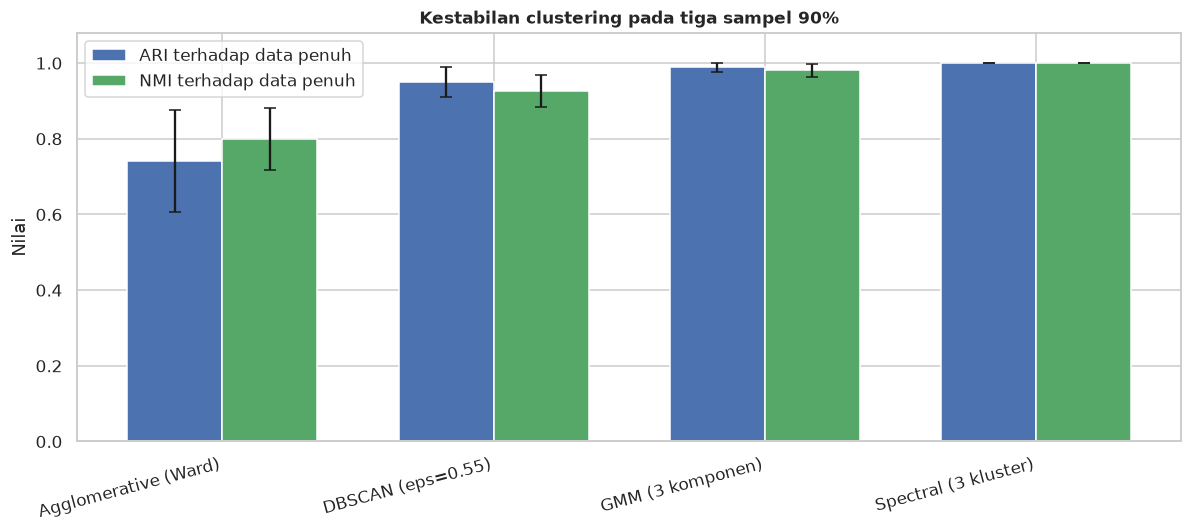

In [19]:
def fit_labels_for_stability(name, X_subset):
    if name == "Agglomerative (Ward)":
        return AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X_subset)
    if name.startswith("DBSCAN"):
        return DBSCAN(eps=DBSCAN_EPS, min_samples=DBSCAN_MIN_SAMPLES).fit_predict(X_subset)
    if name.startswith("GMM"):
        return GaussianMixture(
            n_components=3, covariance_type="full", random_state=SEED, n_init=10
        ).fit_predict(X_subset)
    if name.startswith("Spectral"):
        return SpectralClustering(
            n_clusters=3, n_neighbors=10, assign_labels="kmeans", random_state=SEED
        ).fit_predict(X_subset)
    raise ValueError(name)


full_labels = {name: labels for name, labels in algorithm_labels}
stability_rows = []
run_rows = []

for name, full in full_labels.items():
    aris, nmis, sils, ncls, noises = [], [], [], [], []
    for seed in [42, 43, 44]:
        rng = np.random.RandomState(seed)
        idx = rng.choice(len(X_scaled), size=int(0.9 * len(X_scaled)), replace=False)
        sub_labels = fit_labels_for_stability(name, X_scaled[idx])
        ari = adjusted_rand_score(full[idx], sub_labels)
        nmi = normalized_mutual_info_score(full[idx], sub_labels)
        mask = sub_labels != -1
        sil = (
            silhouette_score(X_scaled[idx][mask], sub_labels[mask])
            if len(set(sub_labels[mask])) > 1
            else np.nan
        )
        n_cluster = len(set(sub_labels[mask]))
        n_noise = int((sub_labels == -1).sum())
        aris.append(ari)
        nmis.append(nmi)
        sils.append(sil)
        ncls.append(n_cluster)
        noises.append(n_noise)
        run_rows.append({
            "algoritma": name,
            "seed": seed,
            "ari_vs_full": ari,
            "nmi_vs_full": nmi,
            "silhouette_subsample": sil,
            "n_clusters": n_cluster,
            "n_noise": n_noise,
        })
    stability_rows.append({
        "algoritma": name,
        "stability_ari_mean": np.mean(aris),
        "stability_ari_std": np.std(aris),
        "stability_nmi_mean": np.mean(nmis),
        "stability_nmi_std": np.std(nmis),
        "subsample_silhouette_mean": np.nanmean(sils),
        "subsample_silhouette_std": np.nanstd(sils),
        "subsample_clusters_mean": np.mean(ncls),
        "subsample_noise_mean": np.mean(noises),
    })

stability_df = pd.DataFrame(stability_rows)
runs_df = pd.DataFrame(run_rows)
display(stability_df.round(4))
display(runs_df.round(4))
stability_df.to_csv(OUTPUT_DIR / "stability_results.csv", index=False)
runs_df.to_csv(OUTPUT_DIR / "stability_runs.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(stability_df))
width = 0.35
ax.bar(
    x - width / 2, stability_df["stability_ari_mean"], width,
    yerr=stability_df["stability_ari_std"], capsize=4,
    label="ARI terhadap data penuh", color="#4c72b0",
)
ax.bar(
    x + width / 2, stability_df["stability_nmi_mean"], width,
    yerr=stability_df["stability_nmi_std"], capsize=4,
    label="NMI terhadap data penuh", color="#55a868",
)
ax.set_xticks(x)
ax.set_xticklabels(stability_df["algoritma"], rotation=15, ha="right")
ax.set_ylim(0, 1.08)
ax.set_ylabel("Nilai")
ax.set_title("Kestabilan clustering pada tiga sampel 90%", fontsize=11, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "stability_comparison.png", bbox_inches="tight")
plt.show()

# Kesimpulan

Empat algoritma clustering telah diterapkan pada 342 baris data penguin yang bersih dan distandardisasi. GMM dengan tiga komponen memberikan keseimbangan terbaik: Silhouette 0,4545, Rand Index 0,9817, NMI 0,9349, dan ARI 0,9603. GMM memisahkan Gentoo dengan sempurna dan hanya menempatkan lima penguin Adelie atau Chinstrap pada kluster yang salah.

Agglomerative Ward juga kuat dengan Rand Index 0,9608 dan NMI 0,9007, tetapi kestabilannya lebih rendah, yaitu ARI 0,7406 pada sampel 90%. Spectral memiliki Silhouette tertinggi, 0,4624, dan sangat stabil, tetapi NMI-nya hanya 0,8312 karena batas Adelie dan Chinstrap kurang tepat. DBSCAN dengan eps 0,55 menghasilkan Silhouette 0,4998 pada 296 titik non-noise dan NMI 0,7386 pada seluruh titik, tetapi membuang 46 titik sebagai noise.

Secara keseluruhan, GMM paling cocok untuk dataset ini karena memakai seluruh data, memisahkan Gentoo dengan sangat baik, memiliki metrik eksternal tertinggi, dan stabil pada sampel 90%.

## Saran Pengembangan

+ Membandingkan GMM dengan variasi `covariance_type`, misalnya `tied` atau `diag`, untuk melihat apakah model yang lebih sederhana tetap akurat.
+ Menambahkan validasi silang dan bootstrap yang lebih banyak agar estimasi kestabilan tidak bergantung pada tiga sampel saja.
+ Menguji algoritma pada fitur rasio, misalnya rasio panjang dan kedalaman paruh, karena rasio dapat mengurangi pengaruh ukuran tubuh.
+ Menambahkan analisis jumlah kluster optimal dengan Silhouette, BIC, dan Davies-Bouldin sebelum memilih tiga kluster.
+ Memvalidasi hasil pada data penguin yang lebih baru atau populasi lain untuk melihat apakah struktur kluster bersifat umum.

# Penutup - File Output

Seluruh gambar dan tabel evaluasi disimpan di folder `output/`. File utama adalah `clustering_metrics.csv`, `stability_results.csv`, `dbscan_eps_sweep.csv`, dan `cluster_assignments.csv`.

In [20]:
for path in sorted(OUTPUT_DIR.glob("*")):
    print(f" - {path.name} ({path.stat().st_size / 1024:.1f} KB)")

 - cleaning_summary.csv (0.1 KB)
 - cluster_assignments.csv (19.0 KB)
 - cluster_comparison.png (231.2 KB)
 - clustering_metrics.csv (0.5 KB)
 - dbscan_eps_sweep.csv (1.8 KB)
 - dbscan_eps_sweep.png (67.8 KB)
 - dendrogram.png (35.6 KB)
 - feature_stats.csv (0.4 KB)
 - gmm_species_crosstab.csv (0.1 KB)
 - gmm_species_heatmap.png (27.2 KB)
 - initial_scatter.png (128.0 KB)
 - metrics_comparison.png (54.4 KB)
 - missing_values.png (34.4 KB)
 - scaled_feature_stats.csv (0.6 KB)
 - scaling_comparison.png (60.8 KB)
 - species_counts.csv (0.1 KB)
 - stability_comparison.png (62.0 KB)
 - stability_results.csv (0.7 KB)
 - stability_runs.csv (1.0 KB)
